شکل‌ها: (2030, 64, 188, 1) (423, 64, 188, 1) (509, 64, 188, 1)
class weight: {0: np.float64(0.533508541392904), 1: np.float64(3.3008130081300813), 2: np.float64(0.5702247191011236), 3: np.float64(1.395189003436426), 4: np.float64(2.839160839160839)}
Epoch 1/80
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 269ms/step - accuracy: 0.4507 - loss: 1.4258 - val_accuracy: 0.1678 - val_loss: 1.9752 - learning_rate: 5.0000e-04
Epoch 2/80
64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 255ms/step - accuracy: 0.5182 - loss: 1.2905 - val_accuracy: 0.1182 - val_loss: 2.6597 - learning_rate: 5.0000e-04
Epoch 3/80
64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 252ms/step - accuracy: 0.5438 - loss: 1.2235 - val_accuracy: 0.1820 - val_loss: 3.0029 - learning_rate: 5.0000e-04
Epoch 4/80
64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 254ms/step - accuracy: 0.5409 - loss: 1.2004 - val_accuracy: 0.1537 - val_loss: 4.0980 - learning_rate: 5.0000e-04
Epoch 5/80
64/64 ━━━━━━━━━━━━━━━━━━━━ 16s 253ms/step - accuracy: 0.5892 - loss: 1.1814 - val_accuracy: 0.1135 - val_loss: 

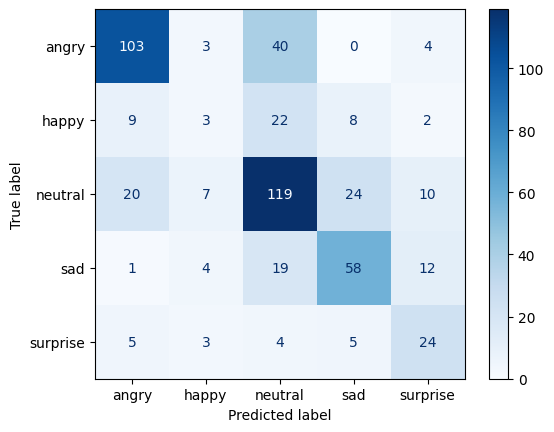

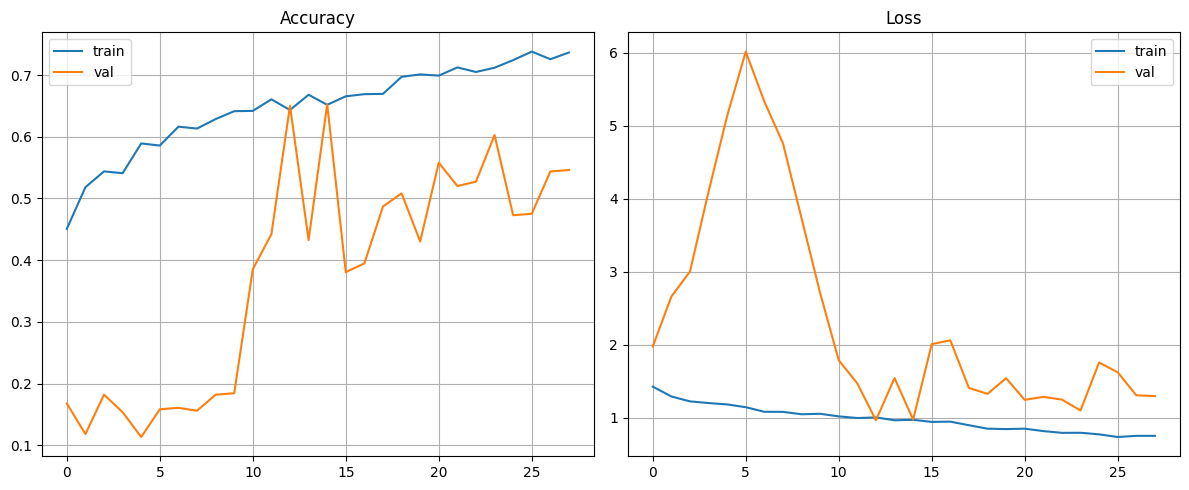

In [26]:
from pathlib import Path

import keras
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

# ---------- تنظیمات ----------
ROOT = Path("voice_datasets")          # مسیر پوشه‌ی اصلی (شامل female و male)
CLASSES = ["angry", "happy", "neutral", "sad", "surprise"]
EMOTION_MAP = {"A": "angry", "H": "happy", "N": "neutral", "S": "sad", "W": "surprise"}
SR, DURATION, N_MELS = 16000, 3, 64
MAX_LEN = SR * DURATION
CACHE = Path("shemo_mel.npz")


# ---------- ۱. جدول فایل‌ها ----------
def build_dataframe():
    rows = []
    for gender in ["female", "male"]:
        for wav in (ROOT / gender).rglob("*.wav"):
            label = EMOTION_MAP.get(wav.stem[3])
            if label:  # fear حذف می‌شه
                rows.append({"path": str(wav), "label": label, "speaker": wav.stem[:3]})
    return pd.DataFrame(rows)


# ---------- ۲. تقسیم بر اساس گوینده ----------
def split_by_speaker(df):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    tv_idx, test_idx = next(sgkf.split(df, df.label, groups=df.speaker))
    train_val, test = df.iloc[tv_idx], df.iloc[test_idx]

    sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    tr_idx, val_idx = next(sgkf2.split(train_val, train_val.label, groups=train_val.speaker))
    return train_val.iloc[tr_idx], train_val.iloc[val_idx], test


# ---------- ۳. استخراج ویژگی ----------
def wav_to_mel(path):
    y, _ = librosa.load(path, sr=SR)
    y, _ = librosa.effects.trim(y, top_db=30)
    y = np.pad(y, (0, max(0, MAX_LEN - len(y))))[:MAX_LEN]
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS, n_fft=1024, hop_length=256)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    return ((mel_db + 80) / 80).astype("float32")


def build_arrays(d):
    X = np.stack([wav_to_mel(p) for p in d.path])[..., None]
    y = d.label.map({c: i for i, c in enumerate(CLASSES)}).values
    return X, y


# ---------- ۴. SpecAugment ----------
class SpecAugment(layers.Layer):
    """چند نوار تصادفی از زمان و فرکانس رو صفر می‌کنه (فقط حین آموزش)."""

    def __init__(self, max_time=30, max_freq=10, **kwargs):
        super().__init__(**kwargs)
        self.max_time = max_time
        self.max_freq = max_freq

    def _band_mask(self, size, max_width, batch):
        width = tf.random.uniform([batch, 1], 1, max_width + 1, dtype=tf.int32)
        start = tf.random.uniform([batch, 1], 0, 1 << 30, dtype=tf.int32) % tf.maximum(size - width, 1)
        idx = tf.range(size)[None, :]
        return (idx >= start) & (idx < start + width)          # (batch, size)

    def call(self, x, training=None):
        if not training:
            return x
        shape = tf.shape(x)
        batch, freq, time = shape[0], shape[1], shape[2]
        f_mask = self._band_mask(freq, self.max_freq, batch)[:, :, None, None]
        t_mask = self._band_mask(time, self.max_time, batch)[:, None, :, None]
        return tf.where(f_mask | t_mask, tf.zeros_like(x), x)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"max_time": self.max_time, "max_freq": self.max_freq})
        return cfg


# ---------- ۵. مدل ----------
def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout)(x)


def build_model(input_shape, norm_layer):
    inputs = keras.Input(shape=input_shape)
    x = norm_layer(inputs)
    x = SpecAugment()(x)
    for filters, drop in [(32, 0.20), (64, 0.25), (128, 0.30)]:
        x = conv_block(x, filters, drop)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs)


# ---------- اجرا ----------
if CACHE.exists():
    d = np.load(CACHE)
    X_train, y_train = d["X_train"], d["y_train"]
    X_val, y_val = d["X_val"], d["y_val"]
    X_test, y_test = d["X_test"], d["y_test"]
else:
    df = build_dataframe()
    print(df.label.value_counts())
    train, val, test = split_by_speaker(df)
    for name, part in [("train", train), ("val", val), ("test", test)]:
        print(name, len(part), part.speaker.nunique(), "گوینده", part.label.value_counts().to_dict())

    X_train, y_train = build_arrays(train)
    X_val, y_val = build_arrays(val)
    X_test, y_test = build_arrays(test)
    np.savez_compressed(CACHE, X_train=X_train, y_train=y_train,
                        X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

print("شکل‌ها:", X_train.shape, X_val.shape, X_test.shape)

weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weight = dict(enumerate(weights))
print("class weight:", class_weight)

norm = layers.Normalization(axis=None)
norm.adapt(X_train)

model = build_model(X_train.shape[1:], norm)
model.compile(optimizer=Adam(5e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("best_ser_model.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6),
]

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=80, batch_size=32, class_weight=class_weight, callbacks=callbacks)

# ---------- ارزیابی ----------
train_acc = (np.argmax(model.predict(X_train, verbose=0), axis=1) == y_train).mean()
print(f"train acc (حالت پیش‌بینی): {train_acc:.2%}")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=CLASSES, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASSES).plot(cmap="Blues")
plt.savefig("confusion_matrix_ser.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend(); plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend(); plt.grid(True)
plt.tight_layout()
plt.savefig("training_curves_ser.png", dpi=150)
plt.show()

In [27]:
model.save("ser_final.keras")

In [34]:

import numpy as np
import librosa
import subprocess
import imageio_ffmpeg
import tempfile
import os

def predict_emotion(audio_path):
    # استخراج صدای MP4 و تبدیل به WAV موقت
    ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

    with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as temp:
        temp_wav = temp.name

    try:
        subprocess.run([
            ffmpeg, "-y",
            "-i", audio_path,
            "-vn", "-ac", "1", "-ar", "16000",
            "-c:a", "pcm_s16le",
            temp_wav
        ], check=True, capture_output=True)

        # خواندن صدای تبدیل‌شده
        y, _ = librosa.load(temp_wav, sr=16000)
    finally:
        if os.path.exists(temp_wav):
            os.remove(temp_wav)

    # پردازش مطابق آموزش مدل
    y, _ = librosa.effects.trim(y, top_db=30)

    max_len = 16000 * 3
    y = np.pad(y, (0, max(0, max_len - len(y))))[:max_len]

    mel = librosa.feature.melspectrogram(
        y=y, sr=16000, n_mels=64,
        n_fft=1024, hop_length=256
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel = ((mel_db + 80) / 80).astype("float32")
    mel = mel[np.newaxis, ..., np.newaxis]

    probabilities = model.predict(mel, verbose=0)[0]
    best_index = np.argmax(probabilities)

    print("احساس پیش‌بینی‌شده:", CLASSES[best_index])
    print("\nاحتمال هر کلاس:")
    for emotion, probability in zip(CLASSES, probabilities):
        print(f"{emotion}: {probability:.1%}")


print("مدل:", model is not None)
print("کلاس‌ها:", CLASSES)
print("شروع تست فایل...")

predict_emotion("my_voice.wav")

print("پایان تست")

مدل: True
کلاس‌ها: ['angry', 'happy', 'neutral', 'sad', 'surprise']
شروع تست فایل...
احساس پیش‌بینی‌شده: neutral

احتمال هر کلاس:
angry: 3.4%
happy: 1.7%
neutral: 73.9%
sad: 20.1%
surprise: 0.8%
پایان تست
